In [ ]:
!rm -f /content/datasets.zip
!gdown 1q0r6yeHQMS17R3wz-s2FIbMR5DAGZK5v -O /content/datasets.zip
!ls -lh /content/datasets.zip
!unzip -q /content/datasets.zip -d /content/datasets
!ls /content/datasets

Downloading...
From (original): https://drive.google.com/uc?id=1q0r6yeHQMS17R3wz-s2FIbMR5DAGZK5v
From (redirected): https://drive.google.com/uc?id=1q0r6yeHQMS17R3wz-s2FIbMR5DAGZK5v&confirm=t&uuid=8aec81ef-63c1-4031-a373-6b5a107a13a3
To: /content/datasets.zip
100% 1.10G/1.10G [00:15<00:00, 68.6MB/s]
-rw-r--r-- 1 root root 1.1G Oct  5  2021 /content/datasets.zip
datasets  __MACOSX


In [ ]:
!ls /content/datasets/datasets

test  train  val


In [ ]:
from pathlib import Path
from PIL import Image, ImageOps
from collections import Counter
from torchvision import datasets, transforms

# Colab: zip unpacks to /content/datasets/datasets. Locally: repo raw-data/datasets -> data/
if Path("/content").exists():
    input_dir = Path("/content/datasets/datasets")
    output_dir = Path("/content/processed_datasets")
else:
    repo_root = Path.cwd().resolve().parents[1]  # notebook lives in src/ie4483/
    input_dir = repo_root / "raw-data" / "datasets"
    output_dir = repo_root / "data"

image_size = (224, 224)  # Resize images to 224x224 pixels

supported_formats = (".jpg", ".jpeg", ".png")

def preprocess_images(input_dir, output_dir, image_size):
    if not output_dir.exists():
        output_dir.mkdir(parents=True)
    if not input_dir.exists():
        raise FileNotFoundError(f"Input directory {input_dir} does not exist.")

    input_resolved = input_dir.resolve()
    output_resolved = output_dir.resolve()

    if(input_resolved == output_resolved or input_resolved in output_resolved.parents):
        raise ValueError("Output directory cannot be the same as or a subdirectory of the input directory.")

    image_files = [
        path for path in input_dir.rglob("*") if path.is_file() and path.suffix.lower() in supported_formats
    ]

    if not image_files:
        print("No supported image files found.")
        return

    print(f"Input folder: {input_dir}")
    print(f"Output folder: {output_dir}")
    print(f"Images found: {len(image_files)}")
    print(f"Target size: {image_size[0]}x{image_size[1]}")
    print("Processing images...")

    processed_count = 0
    failed_list = []
    folder_count = Counter()

    for index, image_path in enumerate(image_files, start=1):
        try:
            relative_path = image_path.relative_to(input_dir)

            output_path = (output_dir / relative_path).with_suffix(".jpg")  # Ensure output is saved as .jpg

            output_path.parent.mkdir(parents=True, exist_ok=True)

            with Image.open(image_path) as original:
                # Convert to RGB if the image is in a different mode
                image = ImageOps.exif_transpose(original).convert("RGB") if original.mode != "RGB" else ImageOps.exif_transpose(original)

                # Resize the image
                image = ImageOps.fit(image, image_size, method=Image.Resampling.LANCZOS)

                image.save(output_path, format="JPEG", quality=95)

            processed_count += 1
            folder_count[relative_path.parent] += 1

            if index % 100 == 0 or index == len(image_files):
                print(f"Processed {index}/{len(image_files)} images...")

        except Exception as error:
            failed_list.append((str(image_path), str(error)))
            print (f"Failed to process {image_path} -- {error}")

    print(f"\n======== Summary ========")
    print(f"Total images found: {len(image_files)}")
    print(f"Successfully processed: {processed_count}")
    print(f"Failed images: {failed_list}")
    print(f"Output folder: {output_dir}")

    if failed_list:
        print("\nFailed image details:")
        for path, error in failed_list:
            print(f"{path} -- {error}")

    print("\nPreprocessing complete.")


#####  augmentation starts here ######
# Training images: flip + rotate
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),   # flip left-right
    transforms.RandomRotation(15),       # tilt up to 15 degrees
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Validation images: no augmentation
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


if __name__ == "__main__":
    # Preprocess only if not done before
    if not output_dir.exists():
        preprocess_images(input_dir, output_dir, image_size)
    else:
        print("Processed images already exist, skipping preprocessing.")

    # Load images with augmentation
    train_data = datasets.ImageFolder(output_dir / "train", transform=train_transform)
    val_data   = datasets.ImageFolder(output_dir / "val",   transform=val_transform)

    print(train_data.class_to_idx)  # should show {'cat': 0, 'dog': 1}
    print(len(train_data), "training images,", len(val_data), "validation images")

Processed images already exist, skipping preprocessing.
{'cat': 0, 'dog': 1}
20000 training images, 5000 validation images


In [ ]:
!find /content/processed_datasets -maxdepth 3 -type d

/content/processed_datasets
/content/processed_datasets/datasets
/content/processed_datasets/datasets/val
/content/processed_datasets/datasets/val/cat
/content/processed_datasets/datasets/val/dog
/content/processed_datasets/datasets/train
/content/processed_datasets/datasets/train/cat
/content/processed_datasets/datasets/train/dog
/content/processed_datasets/datasets/test


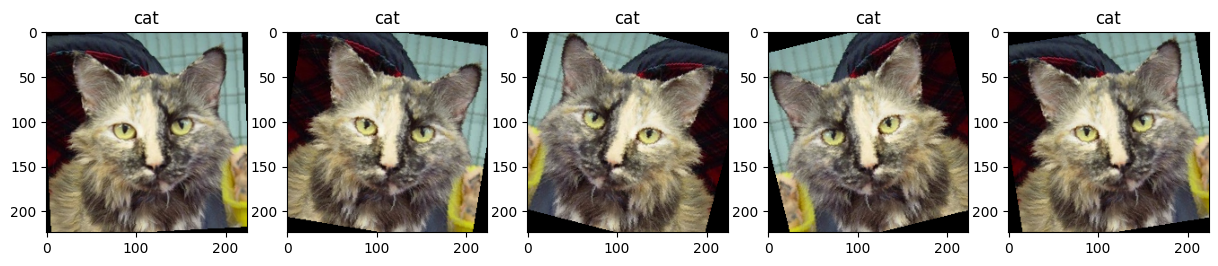

In [ ]:
import matplotlib.pyplot as plt
import torch

# Undo normalization so the colours look normal
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax in axes:
    image, label = train_data[2]                 # same photo, loaded 5 times
    image = (image * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title("dog" if label == 1 else "cat")